# Практична робота № 4. Відкриті міські дані та індикатори сталості
## Розібраний приклад: якість повітря в Харкові, 2021–2023 (PM2.5)

**Питання дослідження.** Як змінювалася якість повітря в Харкові у 2021–2023 роках за індикатором
«середньорічна концентрація дрібнодисперсних частинок PM2.5» (ISO 37120, ЦСР 11.6.2) і чи можна довіряти
цим даним?

**Дані.** Набір data.gov.ua «Щогодинні концентрації та індекс якості атмосферного повітря для дрібнодисперсного
пилу фракції 2.5 мікронів в населених пунктах України» (розпорядник — ГО «SaveDnipro», ліцензія CC BY).

**Конвеєр:** завантаження → очищення → оцінка якості даних → обчислення індикаторів → візуалізація → експорт → висновки.

### Крок 1. Імпорт бібліотек і налаштування

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Шляхи відносно кореня репозиторію
# (ноутбук лежить у папці notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

YEARS = [2021, 2022, 2023]
# Для свого варіанта змініть ці два значення:
CITY_NAME = "Івано-Франківськ"
REGION_NAME = "Івано-Франківська область"

# Нормативи для порівняння, мкг/м³
WHO_ANNUAL = 5       # ВООЗ 2021, середньорічна
WHO_DAILY = 15       # ВООЗ 2021, середньодобова
EU_ANNUAL_2030 = 10  # ЄС з 2030 р., середньорічна
EU_DAILY_2030 = 25   # ЄС з 2030 р., середньодобова

pd.set_option("display.max_columns", 20)
print("pandas", pd.__version__)
print("Файли в data/raw:",
      sorted(p.name for p in RAW.glob("*.csv")))

pandas 3.1.0
Файли в data/raw: ['saveecobot_aqi_cities.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2021.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2022.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2023.csv']


### Крок 2. Довідник населених пунктів: знаходимо ідентифікатор міста

Щогодинні файли містять не назву міста, а числовий ідентифікатор `city_id`. Назви лежать в окремому
довіднику. Це типова структура відкритих даних: **таблиця фактів** (виміри) + **довідник** (опис об'єктів).

In [2]:
cities = pd.read_csv(RAW / "saveecobot_aqi_cities.csv", encoding="utf-8")
print(cities.shape)
cities.head()

(753, 7)


,id,url_slug,type_name,city_name,region_name,koatuu,katottg
0,1,dnipro,місто,Дніпро,Дніпропетровська область,1.210100e+09,UA12020010010037010
1,2,kyiv,місто,Київ,Київ,8.000000e+09,UA80000000000093317
2,3,ivano-frankivsk,місто,Івано-Франківськ,Івано-Франківська область,2.610100e+09,UA26040190010045761
3,4,ternopil,місто,Тернопіль,Тернопільська область,6.110100e+09,UA61040490010069060
4,5,sursko-lytovske,село,Сурсько-Литовське,Дніпропетровська область,1.221488e+09,UA12020290010050775


In [3]:
# Шукаємо за назвою, областю й типом і перевіряємо,
# що знайдено рівно один рядок
match = cities[(cities["city_name"] == CITY_NAME)
               & (cities["region_name"] == REGION_NAME)
               & (cities["type_name"] == "місто")]
assert len(match) == 1, f"Знайдено {len(match)} рядків – уточніть умову"
CITY_ID = int(match["id"].iloc[0])
SLUG = match["url_slug"].iloc[0]
print(f"{CITY_NAME}: city_id = {CITY_ID}, slug = {SLUG}")
match

Івано-Франківськ: city_id = 3, slug = ivano-frankivsk


,id,url_slug,type_name,city_name,region_name,koatuu,katottg
2,3,ivano-frankivsk,місто,Івано-Франківськ,Івано-Франківська область,2.610100e+09,UA26040190010045761


### Крок 3. Завантаження щогодинних даних

Кожен річний файл містить дані **всіх** населених пунктів (30–50 МБ). Щоб не тримати в пам'яті зайве,
читаємо лише потрібні стовпці з явними типами даних і одразу відбираємо своє місто.

In [4]:
def read_year(year: int) -> pd.DataFrame:
    name = f"saveecobot_cities_pm25_and_aqi_pm25_{year}.csv"
    df = pd.read_csv(
        RAW / name,
        encoding="utf-8",
        sep=",",
        usecols=["city_id", "pm25", "logged_at"],
        dtype={"city_id": "int32", "pm25": "float64",
               "logged_at": "string"},
    )
    print(f"{year}: усього {len(df):>9,} рядків", end=" → ")
    df = df[df["city_id"] == CITY_ID]
    print(f"для міста {len(df):,}")
    return df


raw = pd.concat([read_year(y) for y in YEARS], ignore_index=True)
raw.info()
raw.head()

2021: усього 1,435,771 рядків → для міста 8,433
2022: усього   932,415 рядків → для міста 6,269
2023: усього   854,884 рядків → для міста 8,440
<class 'pandas.DataFrame'>
RangeIndex: 23142 entries, 0 to 23141
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   city_id    23142 non-null  int32  
 1   pm25       23005 non-null  float64
 2   logged_at  23142 non-null  string 
dtypes: float64(1), int32(1), string(1)
memory usage: 452.1 KB


,city_id,pm25,logged_at
0,3,19.9925,2021-01-01 00:00:00
1,3,19.3300,2021-01-01 01:00:00
2,3,19.7850,2021-01-01 02:00:00
3,3,14.3788,2021-01-01 03:00:00
4,3,14.7838,2021-01-01 04:00:00


### Крок 4. Очищення даних

Перевіряємо: типи даних, пропуски, неможливі значення, дублікати, порядок записів.

In [5]:
df = raw.copy()
df["logged_at"] = pd.to_datetime(df["logged_at"], format="%Y-%m-%d %H:%M:%S")

print("Пропуски за стовпцями:\n", df.isna().sum(), sep="")
bad = df[(df["pm25"] < 0) | (df["pm25"] > 1000)]
print("Неможливих значень:", len(bad))
print("Повних дублікатів рядків:", df.duplicated().sum())
print("Повторів години:", df.duplicated(subset=["logged_at"]).sum())

Пропуски за стовпцями:
city_id        0
pm25         137
logged_at      0
dtype: int64
Неможливих значень: 0
Повних дублікатів рядків: 6
Повторів години: 6


In [6]:
df = (df.drop_duplicates(subset=["logged_at"])
        .loc[lambda d: d["pm25"].between(0, 1000)]
        .sort_values("logged_at")
        .set_index("logged_at"))
print(len(raw), "→", len(df), "рядків після очищення")
df["pm25"].describe().round(1)

23142 → 22999 рядків після очищення


count    22999.0
mean        14.1
std         15.2
min          0.2
25%          4.8
50%          9.2
75%         17.6
max        199.1
Name: pm25, dtype: float64

### Крок 5. Оцінка якості даних: повнота

**Повнота (completeness)** — частка годин, для яких є вимір. Індикатор, обчислений на неповних даних,
може бути зміщеним: якщо пропущено переважно зимові місяці, середньорічне значення буде заниженим.

In [7]:
# 1 — у цю годину є вимір, 0 — немає
hours = df["pm25"].resample("h").count()

monthly_completeness = (hours.resample("MS").mean() * 100).round(1)
completeness_table = (
    monthly_completeness.to_frame("повнота_%")
    .assign(рік=lambda t: t.index.year, місяць=lambda t: t.index.month)
    .pivot(index="місяць", columns="рік", values="повнота_%"))
completeness_table

рік,2021,2022,2023
місяць,,,
1,100.0,15.6,98.8
2,100.0,24.3,73.1
3,99.7,98.8,76.6
4,100.0,100.0,100.0
5,100.0,100.0,100.0
6,100.0,69.4,100.0
7,99.7,0.0,100.0
8,97.0,52.3,100.0
9,95.7,100.0,100.0


In [8]:
# Найдовші пропуски: послідовності годин без вимірів
missing = hours.eq(0)
gap_id = (missing != missing.shift()).cumsum()
gaps = (missing[missing].groupby(gap_id[missing])
        .agg(початок=lambda s: s.index.min(), тривалість_год="size")
        .sort_values("тривалість_год", ascending=False)
        .reset_index(drop=True))
gaps.head(5)

,початок,тривалість_год
0,2022-06-21 20:00:00,1319
1,2022-01-20 08:00:00,231
2,2022-01-04 20:00:00,164
3,2022-01-30 01:00:00,160
4,2023-03-16 14:00:00,116


### Крок 6. Середньодобові значення

За поширеним правилом (зокрема в практиці ЄС) середньодобове значення вважається дійсним,
якщо є щонайменше **18 із 24** годинних вимірів (75 %).

In [9]:
daily = df["pm25"].resample("D").agg(["mean", "count"])
daily["valid"] = daily["count"] >= 18
daily.loc[~daily["valid"], "mean"] = float("nan")
print("Недійсних діб:", (~daily["valid"]).sum(), "з", len(daily))
daily.head()

Недійсних діб: 153 з 1095


,mean,count,valid
logged_at,,,
2021-01-01,24.847046,24,True
2021-01-02,35.170283,24,True
2021-01-03,46.230062,24,True
2021-01-04,51.551454,24,True
2021-01-05,9.671108,24,True


### Крок 7. Обчислення індикаторів

| Індикатор | Методика |
|---|---|
| Середньорічна концентрація PM2.5 | середнє дійсних середньодобових значень за рік (ISO 37120, ЦСР 11.6.2) |
| Повнота даних | частка дійсних діб у році; річне значення вважаємо надійним при ≥ 90 % |
| Дні з перевищенням настанови ВООЗ | кількість діб із середньодобовою концентрацією > 15 мкг/м³ (ВООЗ допускає 3–4 на рік) |
| Дні з перевищенням граничної величини ЄС-2030 | кількість діб > 25 мкг/м³ (допускається до 18 на рік) |

In [10]:
def who_level(x: float) -> str:
    """Рівень за проміжними цілями ВООЗ (Interim Targets)."""
    levels = [(5, "настанова ВООЗ"), (10, "IT-4"),
              (15, "IT-3"), (25, "IT-2"), (35, "IT-1")]
    for limit, name in levels:
        if x <= limit:
            return name
    return "гірше IT-1"


ind = daily.groupby(daily.index.year).agg(
    середньорічна_pm25=("mean", "mean"),
    дійсних_діб=("valid", "sum"),
    діб_у_році=("valid", "size"),
    діб_понад_15=("mean", lambda s: (s > WHO_DAILY).sum()),
    діб_понад_25=("mean", lambda s: (s > EU_DAILY_2030).sum()),
)
ind["повнота_%"] = (ind["дійсних_діб"] / ind["діб_у_році"] * 100).round(1)
ind["надійно"] = ind["повнота_%"] >= 90
ind["рівень_ВООЗ"] = ind["середньорічна_pm25"].apply(who_level)
ind["у_разів_вище_ВООЗ"] = (ind["середньорічна_pm25"] / WHO_ANNUAL).round(1)
ind["середньорічна_pm25"] = ind["середньорічна_pm25"].round(1)
ind.index.name = "рік"
ind

,середньорічна_pm25,дійсних_діб,діб_у_році,діб_понад_15,діб_понад_25,повнота_%,надійно,рівень_ВООЗ,у_разів_вище_ВООЗ
рік,,,,,,,,,
2021,15.8,341,365,120,68,93.4,True,IT-2,3.2
2022,13.3,254,365,79,30,69.6,False,IT-3,2.7
2023,12.7,347,365,90,31,95.1,True,IT-3,2.5


### Крок 8. Візуалізація

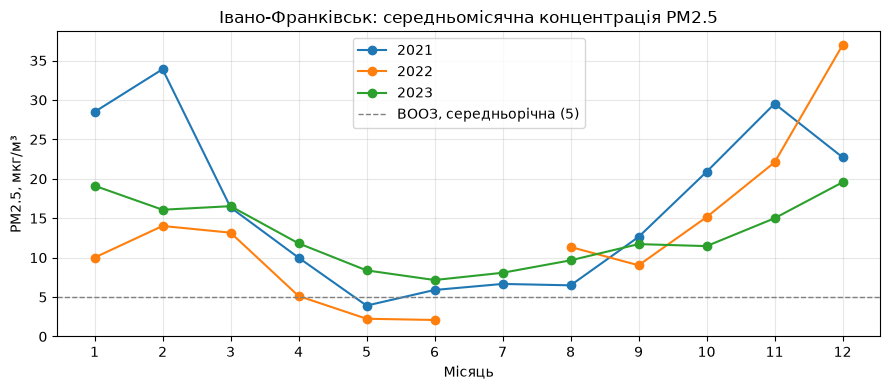

In [11]:
monthly = daily["mean"].resample("MS").mean()
fig, ax = plt.subplots(figsize=(9, 4))
for year in YEARS:
    m = monthly[monthly.index.year == year]
    ax.plot(m.index.month, m.values, marker="o", label=str(year))
ax.axhline(WHO_ANNUAL, ls="--", color="gray", lw=1,
           label="ВООЗ, середньорічна (5)")
ax.set_ylim(bottom=0)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Місяць")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: середньомісячна концентрація PM2.5")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "monthly_pm25.png", dpi=150)
plt.show()

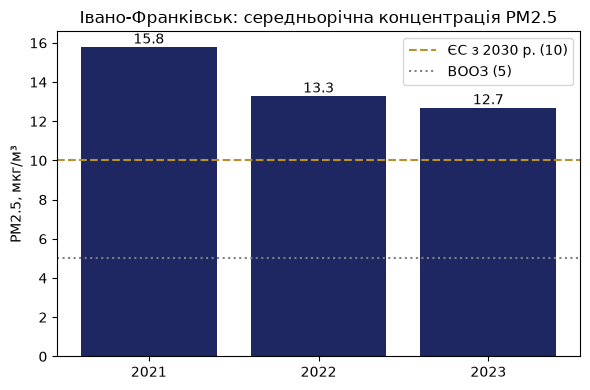

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(ind.index.astype(str), ind["середньорічна_pm25"], color="#1E2761")
ax.bar_label(bars, fmt="%.1f")
ax.axhline(EU_ANNUAL_2030, ls="--", color="#B8912F", label="ЄС з 2030 р. (10)")
ax.axhline(WHO_ANNUAL, ls=":", color="gray", label="ВООЗ (5)")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: середньорічна концентрація PM2.5")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "annual_pm25.png", dpi=150)
plt.show()

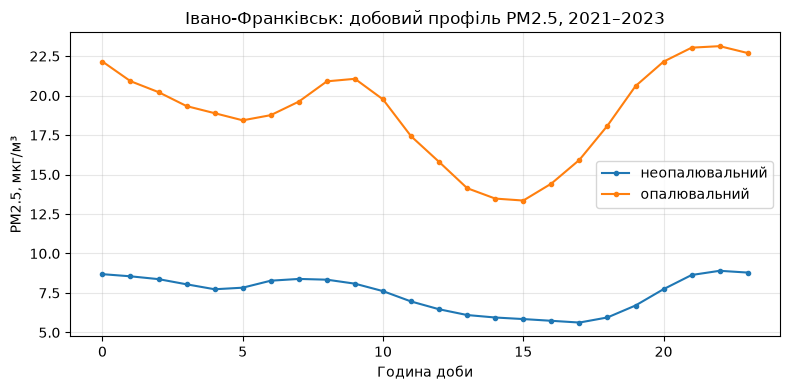

In [13]:
heating = df.index.month.isin([10, 11, 12, 1, 2, 3, 4])
profile = (df.groupby([heating, df.index.hour])["pm25"].mean().unstack(0))
profile.columns = ["неопалювальний", "опалювальний"]
ax = profile.plot(figsize=(8, 4), marker=".")
ax.set_xlabel("Година доби")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: добовий профіль PM2.5, {YEARS[0]}–{YEARS[-1]}")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "diurnal_profile.png", dpi=150)
plt.show()

### Крок 9. Експорт результатів

Очищені середньодобові дані знадобляться в Практичній роботі № 5 (дашборд) і № 7 (геоаналіз).

In [18]:
out = daily.rename(columns={"mean": "pm25_mean", "count": "hours"})
out.to_csv(PROCESSED / f"{SLUG}_pm25_daily.csv")
ind.to_csv(PROCESSED / f"{SLUG}_pm25_indicators.csv")
print("Збережено:", sorted(p.name for p in PROCESSED.glob("*.csv")))

Збережено: ['ivano-frankivsk_pm25_daily.csv', 'ivano-frankivsk_pm25_indicators.csv', 'ivano-frankivsk_pm25_methods.csv']


## Творча частина: вплив пропусків на річне значення

In [15]:
h = hours.to_frame("є_вимір")
h["опалювальний"] = h.index.month.isin([10, 11, 12, 1, 2, 3, 4])
share = (h.groupby([h.index.year, "опалювальний"])["є_вимір"].mean() * 100)
share = share.round(1).unstack()
share.columns = ["неопалювальний", "опалювальний"]
share

,неопалювальний,опалювальний
logged_at,,
2021,98.5,93.8
2022,64.1,75.9
2023,100.0,92.8


In [16]:
methods = pd.DataFrame({
    "усі години": df["pm25"].groupby(df.index.year).mean(),
    "дійсні доби": daily["mean"].groupby(daily.index.year).mean(),
    "середнє місячних": monthly.groupby(monthly.index.year).mean(),
}).round(2)
methods.index.name = "рік"
methods["розмах"] = (methods.max(axis=1) - methods.min(axis=1)).round(2)
methods = methods.join(ind[["повнота_%"]])
methods.to_csv(PROCESSED / f"{SLUG}_pm25_methods.csv")
methods

,усі години,дійсні доби,середнє місячних,розмах,повнота_%
рік,,,,,
2021,16.04,15.85,16.46,0.61,93.4
2022,13.42,13.30,12.84,0.58,69.6
2023,12.71,12.68,12.88,0.20,95.1


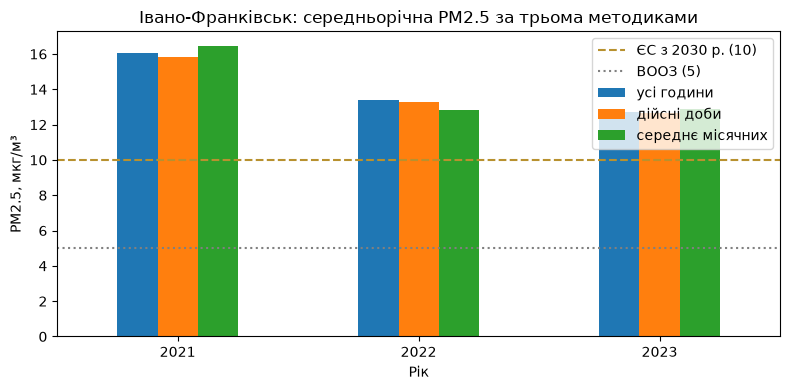

In [17]:
cols = ["усі години", "дійсні доби", "середнє місячних"]
ax = methods[cols].plot(kind="bar", figsize=(8, 4), rot=0)
ax.axhline(EU_ANNUAL_2030, ls="--", color="#B8912F", label="ЄС з 2030 р. (10)")
ax.axhline(WHO_ANNUAL, ls=":", color="gray", label="ВООЗ (5)")
ax.set_xlabel("Рік")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: середньорічна PM2.5 за трьома методиками")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "methods_comparison.png", dpi=150)
plt.show()

### Крок 10. Висновки й обмеження

Висновки записуються у звіт (README.md) з опорою на числа з таблиці індикаторів і графіки.
Обов'язково вкажіть обмеження даних: недорогі сенсори громадян, а не референтні станції; змінна кількість
сенсорів у місті; позначки часу в місцевому часі з переходом на літній час; можливі пропуски
через відключення електроенергії.